<a href="https://colab.research.google.com/github/tettehdaniel/python-labs/blob/main/Notebooks/Notebook17_PredModel_SV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 17 — Introduction to Predictive Modeling

**Main Objective**

1. Supervised Learning Basics

## Setup

Please run the setup code below

In [2]:
! wget -q -nc https://raw.githubusercontent.com/taylor-arnold/fds-py/refs/heads/main/funs.py

from funs import *

In [3]:
import numpy as np
import polars as pl

from plotnine import *
from polars import col as c
theme_set(theme_minimal())

path = "https://raw.githubusercontent.com/ajcollins16/DSST289_Fall2026_AJC/refs/heads/main/"

In [4]:
dat = pl.read_csv(path + "Data/IBM_HR_Analytics.csv")

## Predictive Modeling

In the previous two notebooks, we used ordinary least squares regression primarily for statistical inference. Our goal was to understand how different employee characteristics were related to `MonthlyIncome`, interpret regression coefficients, and determine whether individual predictors provided statistically significant evidence of a relationship.

In this notebook, we will use many of those same regression models but change our goal. Rather than asking whether a relationship exists, we will ask how accurately we can use employee characteristics to predict an employee's `MonthlyIncome`. To accomplish this, our models will be trained using one portion of the data and evaluated using a separate testing portion that the model did not use when estimating its coefficients. Because `MonthlyIncome` is a continuous target, we will evaluate prediction accuracy primarily using root mean squared error (RMSE). Smaller RMSE values indicate that the model's predictions are, on average, closer to the actual monthly incomes. This will be model specific since here we are in the thousands of dollars since we are predicting `MonthlyIncome`.

### Questions

1. In our previous notebooks, we found that `TotalWorkingYears`, `YearsAtCompany`, and `YearsInCurrentRole` could be used as continuous predictors of `MonthlyIncome`. For our first predictive model, create a linear regression model using these previously studied variables to predict `MonthlyIncome`, with `target = c.MonthlyIncome` and the remaining variables serving as `features = [c.TotalWorkingYears, c.YearsAtCompany, c.YearsInCurrentRole]`. Call the outputting model: `model`

In [8]:
model = (
    dat
    .pipe(
        DSSklearn.linear_regression,
        target = c.MonthlyIncome,
        features = [c.TotalWorkingYears, c.YearsAtCompany, c.YearsInCurrentRole]
    )
)

2. Now, fit a inferential linear regression model (like we saw last week) with the same predictors above predicting `MonthlyIncome`.

In [6]:
(
    dat
    .pipe(DSStatsmodels.ols, "MonthlyIncome ~ YearsAtCompany + TotalWorkingYears + YearsInCurrentRole")
)

,coef,std err,t,P>|t|,[0.025,0.975]
str,f64,f64,f64,f64,f64,f64
"""Intercept""",1226.4641,144.184,8.506,0.0,943.636,1509.292
"""YearsAtCompany""",56.7189,22.266,2.547,0.011,13.043,100.395
"""TotalWorkingYears""",449.0275,12.864,34.905,0.0,423.793,474.262
"""YearsInCurrentRole""",-43.9498,33.001,-1.332,0.183,-108.684,20.784


3. Use the appropriate model method to display the coefficients estimated by the predictive model made in question 1.

In [9]:
model.coef()

name,param
str,f64
"""Intercept""",6464.963071
"""TotalWorkingYears""",3520.180715
"""YearsAtCompany""",226.94104
"""YearsInCurrentRole""",-55.307823


3. Compare these predictive model coefficients to the normal linear regression model made in question 2. Explain, in your own words why the coefficients themselves are no longer the primary outcome that we care about when our goal changes from statistical inference to prediction.

**Answer (Q3):** Because in the predicitve context, we're more concerned with whether the coefficient collectively produce accurate predictions

4. Use the model's scoring method to obtain the RMSE for both the training and testing datasets.

In [10]:
model.score()

{'train': np.float64(3035.1260049434095),
 'test': np.float64(2849.3919317106925)}

4. Using these printed RMSE values above:

- **First.** What is the RMSE value for the training dataset? **Answer:** 3035.1260049434095
- **Second.** What is the RMSE value for the testing dataset? **Answer:** 2849.3919317106925
- **Third.** Which one is larger? **Answer:** Training
- **Fourth.** How well is the training dataset doing to predict employee monthly income? **Answer:** Not well, overfitting


5. Now add the predictions to the original data using the `.with_columns()` function. Define this new dataset as `dat_pred`.

In [16]:
dat_pred = (
        dat
        .with_columns(
            model.predict()
        )
    )

6. Using the `dat_pred` dataset created in question 5, create a scatterplot with the actual values of MonthlyIncome (target_) on the x-axis and the predicted values (prediction_) on the y-axis, and add a diagonal reference line representing where the predicted and actual values would be identical. To accomplish this last piece use `+ geom_abline(intercept = 0, slope = 1, color = "red", size = 1.5)`.

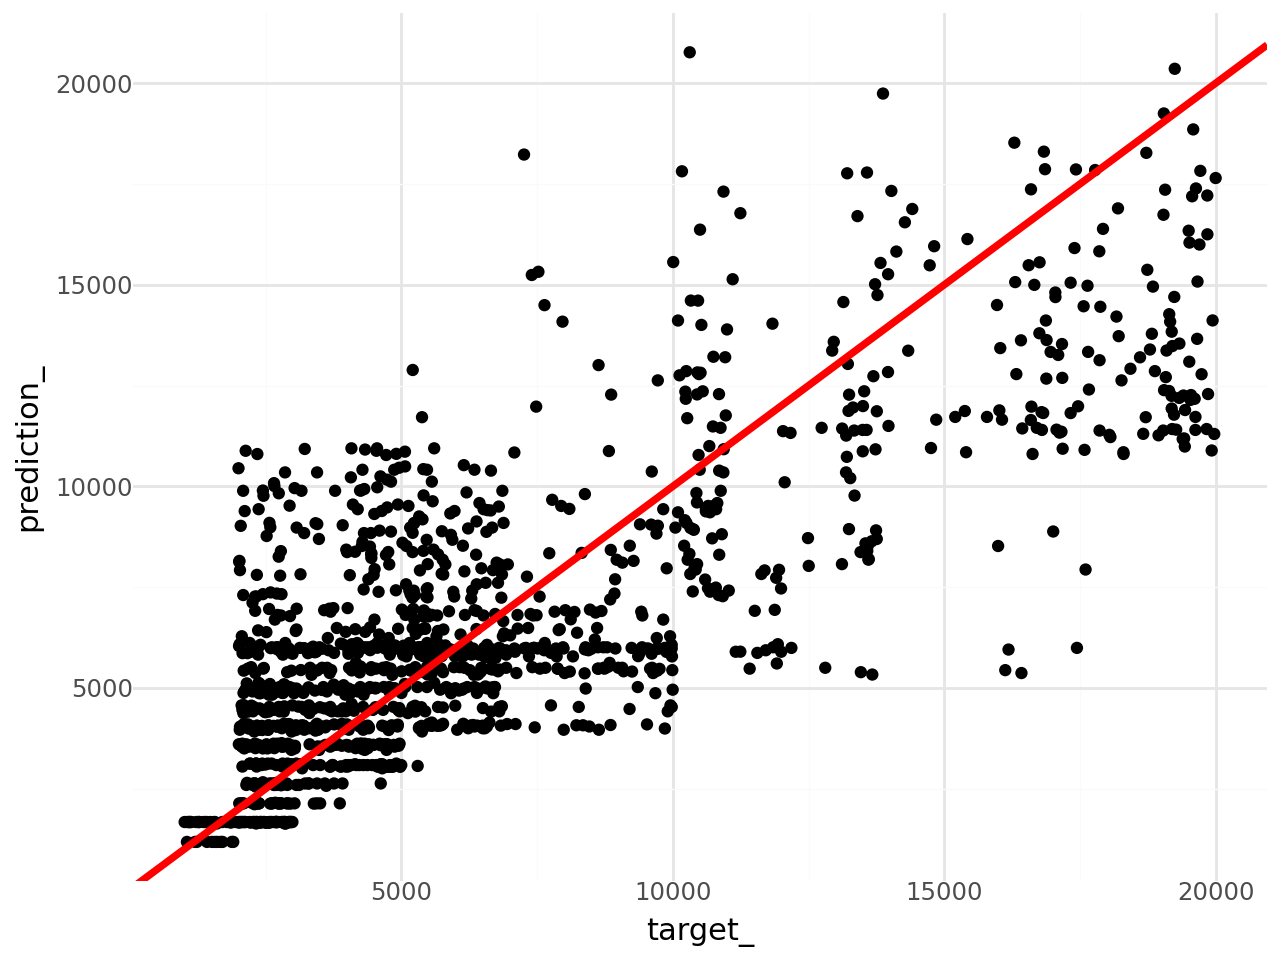

In [18]:
(
    dat_pred
    .pipe(ggplot, aes(x = "target_", y = "prediction_"))
    + geom_point()
    + geom_abline(intercept = 0, slope = 1, color = "red", size = 1.5)
)

6. Based on this visualization, how close do the predictions tend to fall to perfect prediction, and are there portions of the income distribution where the model appears to make larger errors?

**Answers (Q6):** The predictions come quite close.